# Predicting Used Car Prices in Sri Lanka Using Ensemble Learning
### Bagging, Boosting, Stacking and Hybrid Models

**Student:** R D S A Rajapaksha  |  **Index No:** 224155G  

---

## Project Overview
Buying or selling a used car in Sri Lanka is hard to price fairly. Vehicle import restrictions, tax changes and the rupee exchange rate have made prices unpredictable. This project builds machine learning models that **predict the price of a used car** from its details, such as brand, model, year, mileage and engine capacity.

## Dataset
- **Source:** Car listings scraped from **ikman.lk** and **Riyasewana.com**, Sri Lanka's two biggest vehicle marketplaces (Kaggle).
- **Target:** `Price` – listed selling price in Sri Lankan Rupees (LKR).
- **Features:** Brand, Model, Year of Manufacture, Engine (cc), Gear, Fuel Type, Mileage, Town, Date, Leasing, Condition, and comfort features (Air Condition, Power Steering, Power Mirror, Power Window).

## What We Do
1. **Load and clean** the scraped data (fix text-formatted numbers, remove duplicates and unrealistic listings).
2. **Explore** the data to understand what drives car prices in Sri Lanka.
3. **Train and compare** different ensemble learning approaches:
   - **Bagging:** Bagging Regressor, Random Forest, Extra Trees
   - **Boosting:** Gradient Boosting, XGBoost, LightGBM, CatBoost
   - **Stacking:** combining bagging and boosting models with a meta-model
   - **Hybrid models:** Random Forest + Neural Network (ANN), Random Forest + ARIMA (time series)
4. **Evaluate** every model using RMSE, MAE, MAPE and R².
5. **Interpret** the results: which model works best, which features matter most, and **why** each model behaves the way it does.
6. **Save** the best model as a pickle file for the web dashboard.



In [1]:
!pip install xgboost lightgbm catboost kagglehub shap statsmodels -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import kagglehub
import os

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [3]:
# Download the dataset
path = kagglehub.dataset_download("prasadnirmal/srilankan-second-vehiclecar-price-dataset")
print("Downloaded to:", path)

# See which files are inside
print("Files:", os.listdir(path))

# Find the CSV file and load it
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

print("Loaded:", csv_file)
print("Rows and columns:", df.shape)
df.head()

100%|██████████| 150k/150k [00:00<00:00, 56.7MB/s]

Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset/versions/3
Files: ['car_price_dataset.csv']
Loaded: car_price_dataset.csv
Rows and columns: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [4]:
print("Column types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nExample values:")
print(df.sample(5, random_state=1))

Column types:
Unnamed: 0          int64
Brand              object
Model              object
YOM                 int64
Engine (cc)       float64
Gear               object
Fuel Type          object
Millage(KM)       float64
Town               object
Date               object
Leasing            object
Condition          object
AIR CONDITION      object
POWER STEERING     object
POWER MIRROR       object
POWER WINDOW       object
Price             float64
dtype: object

Missing values per column:
Unnamed: 0        0
Brand             0
Model             0
YOM               0
Engine (cc)       0
Gear              0
Fuel Type         0
Millage(KM)       0
Town              0
Date              0
Leasing           0
Condition         0
AIR CONDITION     0
POWER STEERING    0
POWER MIRROR      0
POWER WINDOW      0
Price             0
dtype: int64

Duplicate rows: 0

Example values:
      Unnamed: 0          Brand          Model   YOM  Engine (cc)       Gear  \
5495        5495         SUZUKI  

**Observations:**
- No missing values, and the numeric columns are already stored as numbers.
- `Unnamed: 0` is a leftover row index and can be dropped.
- **Price is in lakhs** (e.g. 43.00 = Rs 4,300,000). It's kept in lakhs, the way Sri Lankans quote car prices.
- Model names include chassis codes (e.g. `COROLLA AE100`), giving 1,475 unique models.
- Yes/No columns use `Available` / `Not_Available`.

In [5]:
start_rows = len(df)

# ---------- 1. Drop index column and rename ----------
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={
    "Engine (cc)": "Engine",
    "Fuel Type": "Fuel",
    "Millage(KM)": "Mileage",
    "AIR CONDITION": "AC",
    "POWER STEERING": "Power_Steering",
    "POWER MIRROR": "Power_Mirror",
    "POWER WINDOW": "Power_Window",
})



# ---------- 3. Tidy text columns ----------
for col in ["Brand", "Model", "Gear", "Fuel", "Town", "Leasing", "Condition"]:
    df[col] = df[col].str.strip().str.upper()

# Base model = first word of the model name (e.g. "COROLLA AE100" -> "COROLLA")
df["Base_Model"] = df["Model"].str.split().str[0]

# ---------- 4. Yes/No columns -> 1/0 ----------
for col in ["AC", "Power_Steering", "Power_Mirror", "Power_Window"]:
    df[col] = (df[col].str.strip() == "Available").astype(int)

df["Leasing"] = (df["Leasing"] != "NO LEASING").astype(int)

# ---------- 5. Date ----------
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# ---------- 6. Remove bad rows ----------
log = []

before = len(df); df = df.drop_duplicates()
log.append(("Duplicate listings", before - len(df)))

before = len(df); df = df[(df["YOM"] >= 1970) & (df["YOM"] <= 2026)]
log.append(("Impossible year", before - len(df)))

before = len(df); df = df[df["Mileage"] <= 1_000_000]
log.append(("Mileage over 1,000,000 km", before - len(df)))

before = len(df); df = df[df["Engine"].between(600, 6500) | (df["Fuel"] == "ELECTRIC")]
log.append(("Unrealistic engine size", before - len(df)))

low, high = df["Price"].quantile([0.01, 0.99])
before = len(df); df = df[df["Price"].between(low, high)]
log.append((f"Price outliers (outside Rs {low:,.0f} - Rs {high:,.0f})", before - len(df)))

df = df.reset_index(drop=True)

# ---------- 7. Summary ----------
print("CLEANING LOG")
for step, removed in log:
    print(f"  {step:<55} removed {removed:>5}")
print(f"\nRows: {start_rows:,} -> {len(df):,}  ({len(df)/start_rows:.1%} kept)")

print("\nDate range:", df["Date"].min().date(), "to", df["Date"].max().date(),
      f"({(df['Date'].max() - df['Date'].min()).days} days)")

print("\nUnique values -> Brands:", df["Brand"].nunique(),
      "| Models:", df["Model"].nunique(),
      "| Base models:", df["Base_Model"].nunique(),
      "| Towns:", df["Town"].nunique())

for col in ["Gear", "Fuel", "Condition"]:
    print(f"\n{col}:", df[col].value_counts().to_dict())

df.head()

CLEANING LOG
  Duplicate listings                                      removed    18
  Impossible year                                         removed    29
  Mileage over 1,000,000 km                               removed     0
  Unrealistic engine size                                 removed     0
  Price outliers (outside Rs 6 - Rs 225)                  removed   189

Rows: 9,788 -> 9,552  (97.6% kept)

Date range: 2024-12-03 to 2025-02-05 (64 days)

Unique values -> Brands: 46 | Models: 1475 | Base models: 502 | Towns: 107

Gear: {'AUTOMATIC': 6196, 'MANUAL': 3356}

Fuel: {'PETROL': 7677, 'HYBRID': 1223, 'DIESEL': 588, 'ELECTRIC': 64}

Condition: {'USED': 9464, 'NEW': 88}


,Brand,Model,YOM,Engine,Gear,Fuel,Mileage,Town,Date,Leasing,Condition,AC,Power_Steering,Power_Mirror,Power_Window,Price,Base_Model
0,AUDI,A1,2016,990.0,AUTOMATIC,PETROL,99000.0,GAMPAHA,2025-02-05,0,USED,1,1,1,1,100.0,A1
1,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,COLOMBO,2025-01-14,0,USED,1,1,1,1,97.0,A1
2,AUDI,A1,2018,1000.0,AUTOMATIC,PETROL,77000.0,DEHIWALA-MOUNT-LAVINIA,2025-01-23,0,USED,1,1,1,1,98.5,A1
3,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,NEGOMBO,2024-12-21,0,USED,1,1,1,1,107.0,A1
4,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,COLOMBO,2024-12-21,0,USED,1,1,1,1,99.5,A1


In [6]:
# Age of the car when it was listed
df["Age"] = df["Date"].dt.year - df["YOM"]
df["Age"] = df["Age"].clip(lower=0)

# Average km driven per year (+1 avoids dividing by zero for brand-new cars)
df["Km_per_year"] = df["Mileage"] / (df["Age"] + 1)

# Number of comfort features (0 to 4)
df["Feature_count"] = df[["AC", "Power_Steering", "Power_Mirror", "Power_Window"]].sum(axis=1)

# Group rare categories into "OTHER"
def group_rare(column, min_count):
    counts = df[column].value_counts()
    rare = counts[counts < min_count].index
    return df[column].replace(rare, "OTHER")

df["Brand"] = group_rare("Brand", 10)
df["Base_Model"] = group_rare("Base_Model", 10)
df["Town"] = group_rare("Town", 20)

# Log of price (used as the target for training)
df["Log_Price"] = np.log(df["Price"])

print("Brands:", df["Brand"].nunique(),
      "| Base models:", df["Base_Model"].nunique(),
      "| Towns:", df["Town"].nunique())
df[["Brand", "Base_Model", "YOM", "Age", "Mileage", "Km_per_year", "Feature_count", "Price", "Log_Price"]].head()

Brands: 31 | Base models: 106 | Towns: 74


,Brand,Base_Model,YOM,Age,Mileage,Km_per_year,Feature_count,Price,Log_Price
0,AUDI,OTHER,2016,9,99000.0,9900.000000,4,100.0,4.605170
1,AUDI,OTHER,2017,8,88000.0,9777.777778,4,97.0,4.574711
2,AUDI,OTHER,2018,7,77000.0,9625.000000,4,98.5,4.590057
3,AUDI,OTHER,2017,7,88000.0,11000.000000,4,107.0,4.672829
4,AUDI,OTHER,2017,7,88000.0,11000.000000,4,99.5,4.600158


## Feature Engineering
- **Age:** age of the car when it was listed (a better price signal than the year itself).
- **Feature_count:** number of comfort features (0–4).
- **Rare categories → "OTHER":** brands and base models with fewer than 10 listings, and towns with fewer than 20. The models can't learn reliably from 1–2 examples.
- **Log_Price:** the target used for training, because prices are heavily skewed.

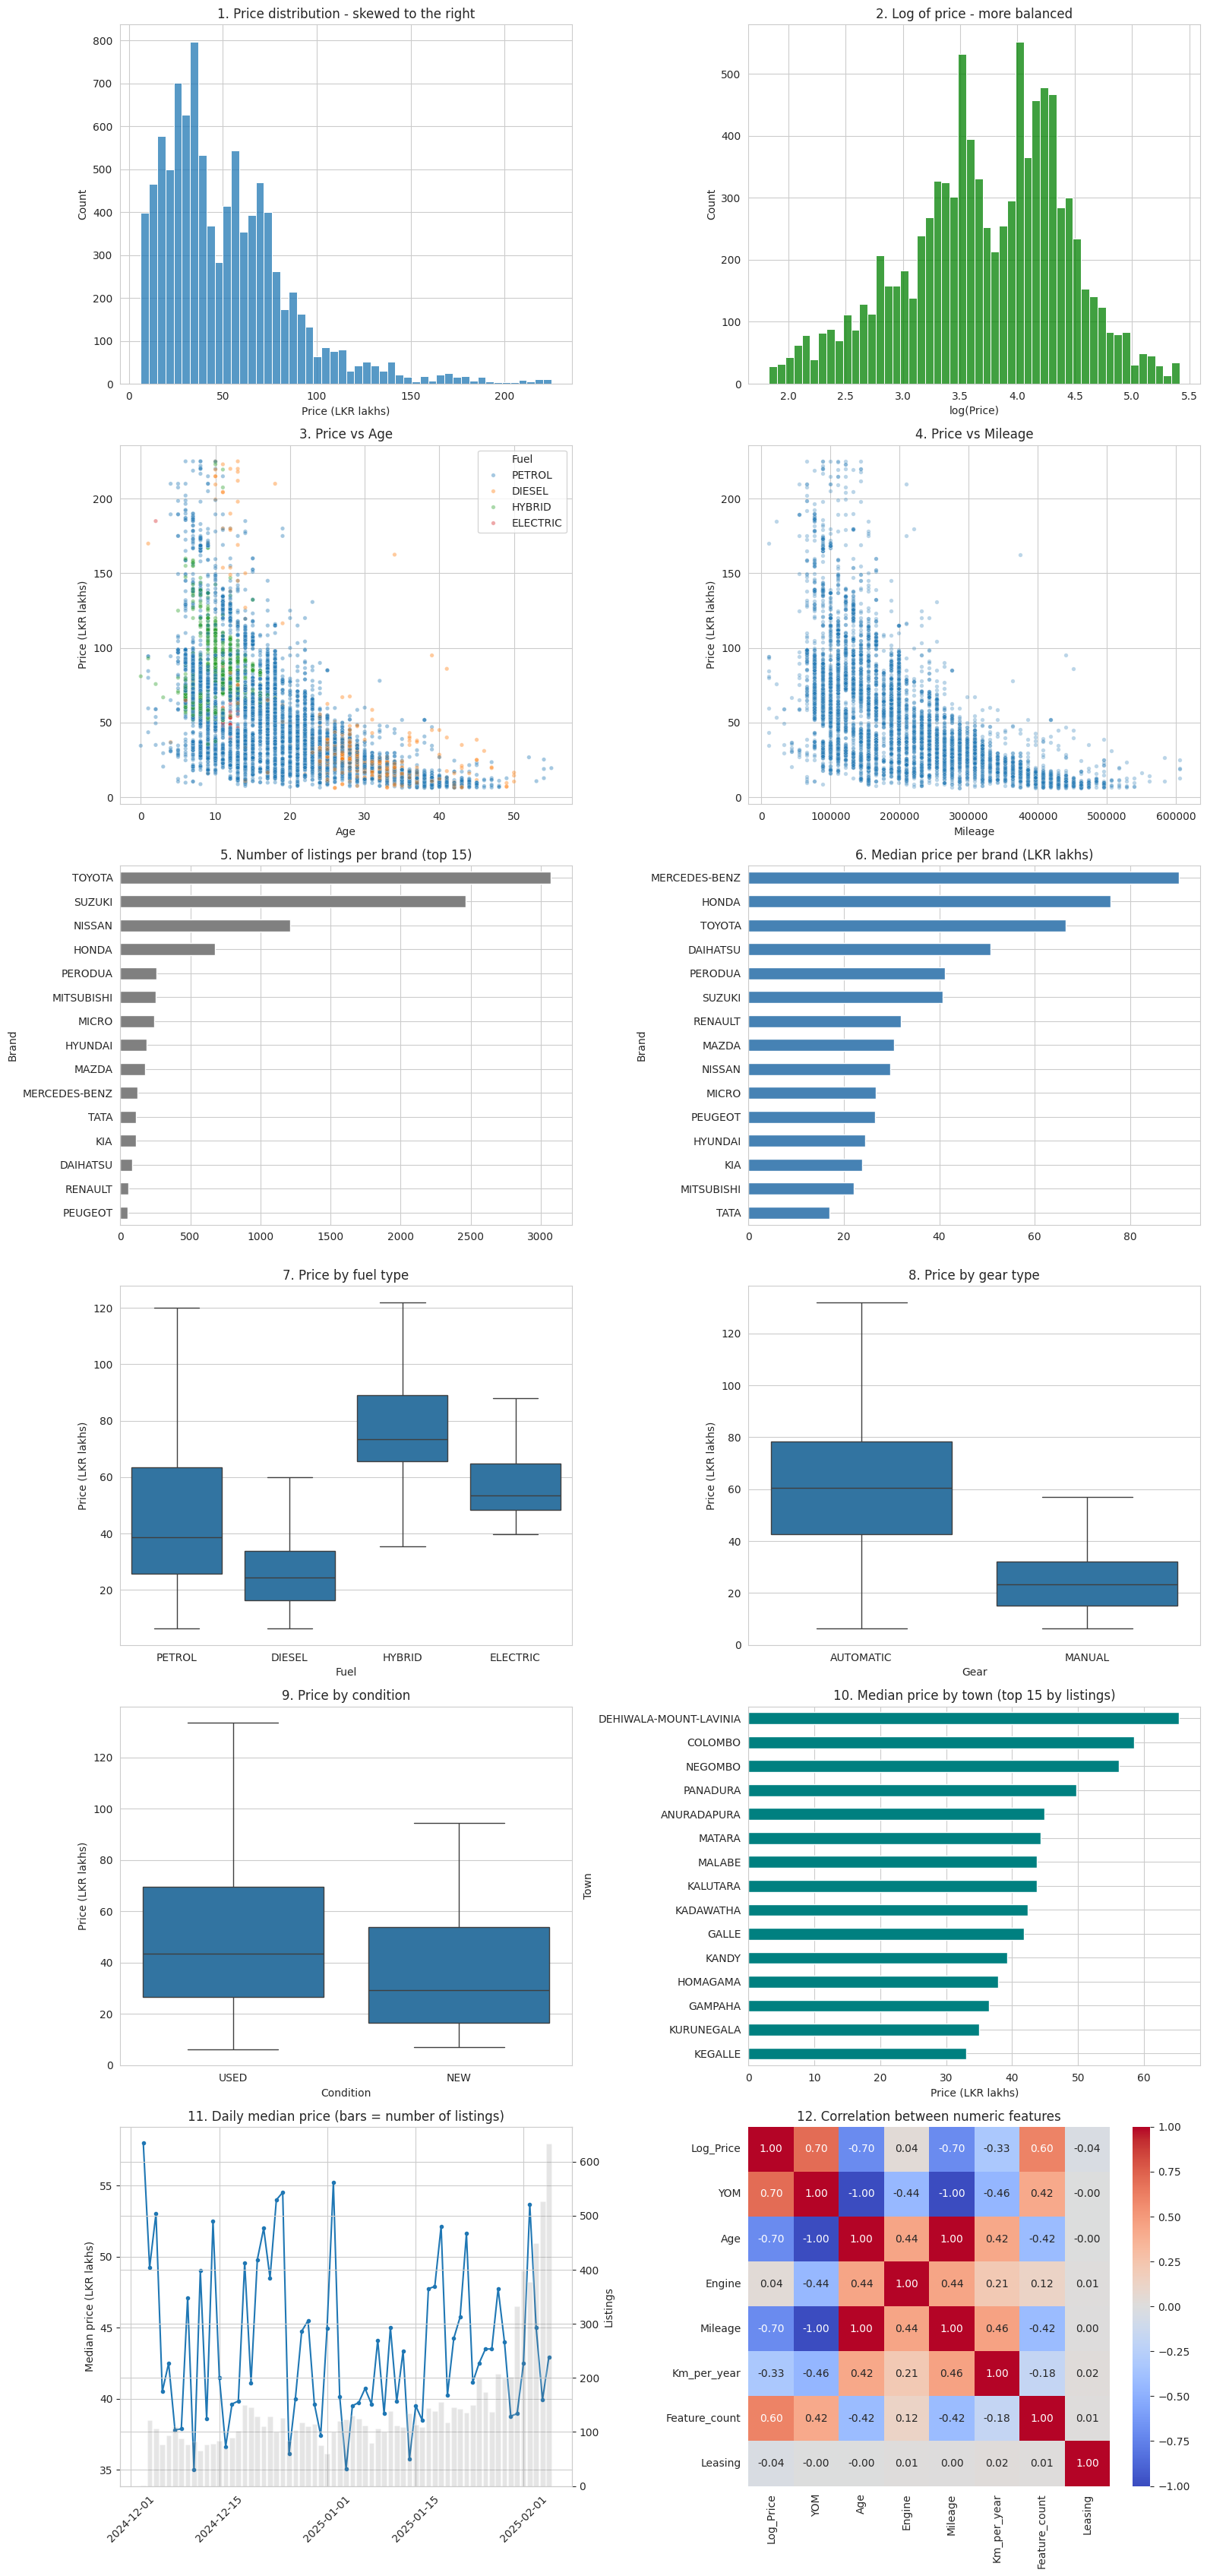

In [7]:
fig, ax = plt.subplots(6, 2, figsize=(16, 34))

# ---------- Row 1: Price distribution ----------
sns.histplot(df["Price"], bins=50, ax=ax[0, 0])
ax[0, 0].set_title("1. Price distribution - skewed to the right")
ax[0, 0].set_xlabel("Price (LKR lakhs)")

sns.histplot(df["Log_Price"], bins=50, ax=ax[0, 1], color="green")
ax[0, 1].set_title("2. Log of price - more balanced")
ax[0, 1].set_xlabel("log(Price)")

# ---------- Row 2: Depreciation ----------
sns.scatterplot(data=df, x="Age", y="Price", hue="Fuel", alpha=0.4, s=15, ax=ax[1, 0])
ax[1, 0].set_title("3. Price vs Age")
ax[1, 0].set_ylabel("Price (LKR lakhs)")

sns.scatterplot(data=df, x="Mileage", y="Price", alpha=0.3, s=15, ax=ax[1, 1])
ax[1, 1].set_title("4. Price vs Mileage")
ax[1, 1].set_ylabel("Price (LKR lakhs)")

# ---------- Row 3: Brands ----------
top_brands = df["Brand"].value_counts().head(15)

top_brands.sort_values().plot(kind="barh", ax=ax[2, 0], color="gray")
ax[2, 0].set_title("5. Number of listings per brand (top 15)")

(df[df["Brand"].isin(top_brands.index)]
   .groupby("Brand")["Price"].median()
   .sort_values()
   .plot(kind="barh", ax=ax[2, 1], color="steelblue"))
ax[2, 1].set_title("6. Median price per brand (LKR lakhs)")

# ---------- Row 4: Fuel and Gear ----------
sns.boxplot(data=df, x="Fuel", y="Price", ax=ax[3, 0], showfliers=False)
ax[3, 0].set_title("7. Price by fuel type")
ax[3, 0].set_ylabel("Price (LKR lakhs)")

sns.boxplot(data=df, x="Gear", y="Price", ax=ax[3, 1], showfliers=False)
ax[3, 1].set_title("8. Price by gear type")
ax[3, 1].set_ylabel("Price (LKR lakhs)")

# ---------- Row 5: Condition and Town ----------
sns.boxplot(data=df, x="Condition", y="Price", ax=ax[4, 0], showfliers=False)
ax[4, 0].set_title("9. Price by condition")
ax[4, 0].set_ylabel("Price (LKR lakhs)")

top_towns = df[df["Town"] != "OTHER"]["Town"].value_counts().head(15).index
(df[df["Town"].isin(top_towns)]
   .groupby("Town")["Price"].median()
   .sort_values()
   .plot(kind="barh", ax=ax[4, 1], color="teal"))
ax[4, 1].set_title("10. Median price by town (top 15 by listings)")
ax[4, 1].set_xlabel("Price (LKR lakhs)")

# ---------- Row 6: Time trend and Correlation ----------
daily = df.groupby("Date").agg(median_price=("Price", "median"),
                               listings=("Price", "count"))

ax[5, 0].plot(daily.index, daily["median_price"], marker="o", markersize=3)
ax[5, 0].set_ylabel("Median price (LKR lakhs)")
ax[5, 0].set_title("11. Daily median price (bars = number of listings)")
ax[5, 0].tick_params(axis="x", rotation=45)
ax_twin = ax[5, 0].twinx()
ax_twin.bar(daily.index, daily["listings"], alpha=0.2, color="gray")
ax_twin.set_ylabel("Listings")

num_cols = ["Log_Price", "YOM", "Age", "Engine", "Mileage", "Km_per_year", "Feature_count", "Leasing"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[5, 1])
ax[5, 1].set_title("12. Correlation between numeric features")

plt.tight_layout()
plt.show()

### Key observations from the EDA

1. **Price is right-skewed** (a few expensive cars), while **log(price) is close to normal**, so the models are trained on log(price).
2. **Steep depreciation** in the first ~15 years, then flattening. Hybrids are mostly 5–15 years old and priced high.
3. **Toyota and Suzuki dominate** the listings. **Mercedes-Benz, Honda and Toyota** have the highest median prices.
4. **Hybrids** have the highest median price (demand driven by fuel costs). **Automatics** cost more than double manuals.
5. **"NEW" cars are cheaper than used ones.** They are likely cheap brand-new small cars (Micro, Tata), and there are only 88 of them.
6. **Colombo-area towns** (Dehiwala-Mount Lavinia, Colombo, Negombo) list the most expensive cars.
7. **The daily median price has no trend** over 64 days, only random ups and downs.
8. **Age (−0.70) and Feature_count (+0.60)** are strongly correlated with price.

---

###  Data-quality finding: Mileage is not real

**How it was identified:**
- In the correlation heatmap (Chart 12), **Mileage vs Age = 1.00** and **Mileage vs YOM = −1.00**. A perfect correlation never happens with real odometer readings
- Checking the sample rows confirmed a fixed pattern of **11,000 km per year of age**:


**Conclusion:** the dataset creator appears to have **filled in mileage from the car's age** instead of using the actual reading.

**Action taken:** **Mileage** and **Km_per_year** are **excluded** from the model inputs, because they carry no information beyond Age.

**Impact:** in reality, mileage strongly affects price (two 2015 cars with 40,000 km and 200,000 km would sell for very different amounts). The models can't learn this, which limits their accuracy. With real mileage data, errors would likely be lower.

In [8]:
cat_cols = ["Brand", "Base_Model", "Gear", "Fuel", "Town", "Condition"]
num_cols = ["Age", "Engine", "Leasing", "AC", "Power_Steering",
            "Power_Mirror", "Power_Window", "Feature_count"]

X_raw = df[cat_cols + num_cols]          # original text columns (for CatBoost)
y = df["Log_Price"]                      # target

X = pd.get_dummies(X_raw, columns=cat_cols, dtype=int)   # one-hot encoded (for all other models)

print("Inputs before encoding:", X_raw.shape[1], "columns")
print("Inputs after one-hot encoding:", X.shape[1], "columns")
X.head()

Inputs before encoding: 14 columns
Inputs after one-hot encoding: 227 columns


,Age,Engine,Leasing,AC,Power_Steering,Power_Mirror,Power_Window,Feature_count,Brand_AUDI,Brand_BMW,...,Town_POLGAHAWELA,Town_POLONNARUWA,Town_PUTTALAM,Town_RAGAMA,Town_RATNAPURA,Town_TANGALLE,Town_WATTALA,Town_WENNAPPUWA,Condition_NEW,Condition_USED
0,9,990.0,0,1,1,1,1,4,1,0,...,0,0,0,0,0,0,0,0,0,1
1,8,1000.0,0,1,1,1,1,4,1,0,...,0,0,0,0,0,0,0,0,0,1
2,7,1000.0,0,1,1,1,1,4,1,0,...,0,0,0,0,0,0,0,0,0,1
3,7,1000.0,0,1,1,1,1,4,1,0,...,0,0,0,0,0,0,0,0,0,1
4,7,1000.0,0,1,1,1,1,4,1,0,...,0,0,0,0,0,0,0,0,0,1


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
import time

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Same rows, original text columns (for CatBoost later)
X_raw_train, X_raw_test = X_raw.loc[X_train.index], X_raw.loc[X_test.index]

print("Training cars:", len(X_train), "| Test cars:", len(X_test))

results = []        # one row of scores per model
trained = {}        # keep every trained model

def evaluate(name, model, group, Xtr=X_train, Xte=X_test):
    start = time.time()
    model.fit(Xtr, y_train)
    train_time = time.time() - start

    # Predict and convert log-price back to lakhs
    pred = np.exp(model.predict(Xte))
    actual = np.exp(y_test)
    train_pred = np.exp(model.predict(Xtr))
    train_actual = np.exp(y_train)

    scores = {
        "Model": name,
        "Group": group,
        "MAE (lakhs)": mean_absolute_error(actual, pred),
        "RMSE (lakhs)": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": mean_absolute_percentage_error(actual, pred) * 100,
        "R2 test": r2_score(actual, pred),
        "R2 train": r2_score(train_actual, train_pred),
        "Time (s)": train_time,
    }
    results.append(scores)
    trained[name] = model

    print(f"{name:<25} MAE = {scores['MAE (lakhs)']:.2f} lakhs | MAPE = {scores['MAPE (%)']:.1f}% | "
          f"R2 test = {scores['R2 test']:.3f} | R2 train = {scores['R2 train']:.3f}")
    return model

Training cars: 7641 | Test cars: 1911


## Baseline Models

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

evaluate("Linear Regression", LinearRegression(), "Baseline")
evaluate("Decision Tree", DecisionTreeRegressor(random_state=42), "Baseline");

Linear Regression         MAE = 6.16 lakhs | MAPE = 14.1% | R2 test = 0.838 | R2 train = 0.901
Decision Tree             MAE = 5.77 lakhs | MAPE = 14.8% | R2 test = 0.850 | R2 train = 0.998


##  Bagging (reducing variance)

In [11]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor

evaluate("Bagging (100 trees)",
         BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=42, n_jobs=-1),
         "Bagging")

evaluate("Random Forest",
         RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1),
         "Bagging")

evaluate("Extra Trees",
         ExtraTreesRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1),
         "Bagging");

Bagging (100 trees)       MAE = 5.05 lakhs | MAPE = 12.2% | R2 test = 0.893 | R2 train = 0.987
Random Forest             MAE = 5.10 lakhs | MAPE = 12.3% | R2 test = 0.896 | R2 train = 0.967
Extra Trees               MAE = 4.85 lakhs | MAPE = 11.7% | R2 test = 0.904 | R2 train = 0.975


## Boosting

In [12]:
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import re

# LightGBM doesn't accept special characters in column names, so make a cleaned copy
clean_name = lambda c: re.sub(r"[^A-Za-z0-9_]", "_", c)
X_train_lgb = X_train.rename(columns=clean_name)
X_test_lgb = X_test.rename(columns=clean_name)

evaluate("Gradient Boosting",
         GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                                   subsample=0.8, random_state=42),
         "Boosting")

evaluate("XGBoost",
         XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8,
                      colsample_bytree=0.8, random_state=42, n_jobs=-1),
         "Boosting")

evaluate("LightGBM",
         LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=31, subsample=0.8,
                       subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1),
         "Boosting", Xtr=X_train_lgb, Xte=X_test_lgb)

evaluate("CatBoost",
         CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6, cat_features=cat_cols,
                           random_seed=42, verbose=0),
         "Boosting", Xtr=X_raw_train, Xte=X_raw_test);

Gradient Boosting         MAE = 5.57 lakhs | MAPE = 13.2% | R2 test = 0.896 | R2 train = 0.950
XGBoost                   MAE = 4.85 lakhs | MAPE = 11.6% | R2 test = 0.910 | R2 train = 0.975
LightGBM                  MAE = 5.22 lakhs | MAPE = 12.5% | R2 test = 0.901 | R2 train = 0.963
CatBoost                  MAE = 5.40 lakhs | MAPE = 12.8% | R2 test = 0.897 | R2 train = 0.947


## Stacking

Stacking (Ridge)          MAE = 4.65 lakhs | MAPE = 11.2% | R2 test = 0.913 | R2 train = 0.977
Voting (average)          MAE = 4.74 lakhs | MAPE = 11.5% | R2 test = 0.909 | R2 train = 0.974

Meta-model weights:
extra_trees      0.370
random_forest   -0.041
xgboost          0.543
lightgbm         0.133
dtype: float64


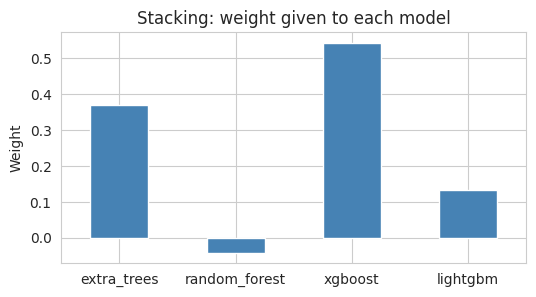

In [13]:
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.linear_model import RidgeCV

base_models = [
    ("extra_trees", ExtraTreesRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1)),
    ("random_forest", RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1)),
    ("xgboost", XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, random_state=42, n_jobs=-1)),
    ("lightgbm", LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=31, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)),
]

stack = evaluate("Stacking (Ridge)",
                 StackingRegressor(estimators=base_models, final_estimator=RidgeCV(), cv=5),
                 "Stacking", Xtr=X_train_lgb, Xte=X_test_lgb)

evaluate("Voting (average)",
         VotingRegressor(estimators=base_models),
         "Stacking", Xtr=X_train_lgb, Xte=X_test_lgb)

# How much the meta-model trusts each base model
weights = pd.Series(stack.final_estimator_.coef_, index=[name for name, _ in base_models])
print("\nMeta-model weights:")
print(weights.round(3))

weights.plot(kind="bar", color="steelblue", figsize=(6, 3), title="Stacking: weight given to each model")
plt.ylabel("Weight")
plt.xticks(rotation=0)
plt.show()

## Hybrid Model 1: Random Forest + Neural Network (ANN)

In [14]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ann = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(128, 64),   # 2 hidden layers: 128 and 64 neurons
                 alpha=0.001,                     # small penalty to reduce overfitting
                 early_stopping=True,             # stop when validation score stops improving
                 max_iter=500,
                 random_state=42)
)

rf = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1)

evaluate("ANN (Neural Network)", ann, "Hybrid RF+ANN")

evaluate("RF + ANN (average)",
         VotingRegressor(estimators=[("rf", rf), ("ann", ann)]),
         "Hybrid RF+ANN")

rf_ann_stack = evaluate("RF + ANN (stacked)",
                        StackingRegressor(estimators=[("rf", rf), ("ann", ann)],
                                          final_estimator=RidgeCV(), cv=5),
                        "Hybrid RF+ANN")

print("\nStacked weights -> RF: {:.3f} | ANN: {:.3f}".format(*rf_ann_stack.final_estimator_.coef_))

ANN (Neural Network)      MAE = 8.60 lakhs | MAPE = 20.2% | R2 test = 0.798 | R2 train = 0.961
RF + ANN (average)        MAE = 6.03 lakhs | MAPE = 14.3% | R2 test = 0.885 | R2 train = 0.973
RF + ANN (stacked)        MAE = 5.04 lakhs | MAPE = 12.2% | R2 test = 0.901 | R2 train = 0.971

Stacked weights -> RF: 0.895 | ANN: 0.118


## Hybrid Model 2: Random Forest + ARIMA (time series)

ARIMA trained on 52 days, tested on 13 days (after 2025-01-23)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autore

Best ARIMA order (p, d, q): (2, 0, 2)


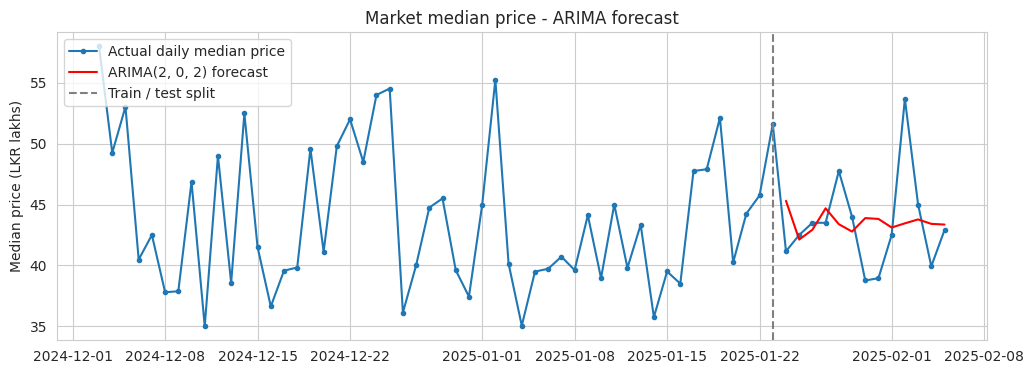

Cars -> train: 5567 | test (newest): 3985


,MAE (lakhs),MAPE (%),R2 test
Model,,,
ARIMA only (market median),25.999,73.329,-0.057
Random Forest only,5.180,12.729,0.906
RF + ARIMA (as feature),5.278,12.942,0.903
RF + ARIMA (residual hybrid),5.359,13.015,0.903


In [16]:
from statsmodels.tsa.arima.model import ARIMA
import itertools

# ---------- 1. Daily market series (median log-price per day) ----------
daily_price = df.groupby("Date")["Log_Price"].median().asfreq("D").interpolate()

split = int(len(daily_price) * 0.8)
train_series, test_series = daily_price[:split], daily_price[split:]
cutoff = train_series.index[-1]
print(f"ARIMA trained on {len(train_series)} days, tested on {len(test_series)} days (after {cutoff.date()})")

# ---------- 2. Pick the best ARIMA(p, d, q) by lowest AIC ----------
best_aic = np.inf
for p, d, q in itertools.product(range(3), range(2), range(3)):
    try:
        model = ARIMA(train_series, order=(p, d, q)).fit()
        if model.aic < best_aic:
            best_aic, best_order, arima = model.aic, (p, d, q), model
    except Exception:
        pass
print("Best ARIMA order (p, d, q):", best_order)

forecast = arima.get_forecast(steps=len(test_series))
forecast_values = pd.Series(forecast.predicted_mean.values, index=test_series.index)

# Plot the forecast
plt.figure(figsize=(12, 4))
plt.plot(np.exp(daily_price), label="Actual daily median price", marker=".")
plt.plot(np.exp(forecast_values), label=f"ARIMA{best_order} forecast", color="red")
plt.axvline(cutoff, color="gray", linestyle="--", label="Train / test split")
plt.ylabel("Median price (LKR lakhs)")
plt.title("Market median price - ARIMA forecast")
plt.legend()
plt.show()

# ---------- 3. Market level for every car (ARIMA fit for past days, forecast for future days) ----------
fitted = arima.fittedvalues.copy()
fitted.iloc[0] = train_series.iloc[0]
market_level = pd.concat([fitted, forecast_values])
df["Market_Level"] = df["Date"].map(market_level)

# ---------- 4. Time-based split of the cars ----------
is_train = df["Date"] <= cutoff
Xt_train, Xt_test = X[is_train], X[~is_train]
yt_train, yt_test = y[is_train], y[~is_train]
mkt_train, mkt_test = df.loc[is_train, "Market_Level"], df.loc[~is_train, "Market_Level"]
print(f"Cars -> train: {len(Xt_train)} | test (newest): {len(Xt_test)}")

ts_results = []
def ts_score(name, pred_log):
    actual, pred = np.exp(yt_test), np.exp(pred_log)
    ts_results.append({"Model": name,
                       "MAE (lakhs)": mean_absolute_error(actual, pred),
                       "MAPE (%)": mean_absolute_percentage_error(actual, pred) * 100,
                       "R2 test": r2_score(actual, pred)})

new_rf = lambda: RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=42, n_jobs=-1)

# A. ARIMA only
ts_score("ARIMA only (market median)", mkt_test)

# B. Random Forest only
ts_score("Random Forest only", new_rf().fit(Xt_train, yt_train).predict(Xt_test))

# C. RF + ARIMA market level as an extra feature
rf_feat = new_rf().fit(Xt_train.assign(Market_Level=mkt_train), yt_train)
ts_score("RF + ARIMA (as feature)", rf_feat.predict(Xt_test.assign(Market_Level=mkt_test)))

# D. RF learns each car's difference from the market level, then add ARIMA back
rf_resid = new_rf().fit(Xt_train, yt_train - mkt_train)
ts_score("RF + ARIMA (residual hybrid)", rf_resid.predict(Xt_test) + mkt_test)

ts_table = pd.DataFrame(ts_results).set_index("Model").round(3)
ts_table

,Group,MAE (lakhs),RMSE (lakhs),MAPE (%),R2 test,R2 train,Time (s),Overfit gap
Model,,,,,,,,
Stacking (Ridge),Stacking,4.655000,10.462000,11.216000,0.913000,0.977000,79.484000,0.065000
Voting (average),Stacking,4.739000,10.656000,11.476000,0.909000,0.974000,15.999000,0.064000
Extra Trees,Bagging,4.848000,10.983000,11.739000,0.904000,0.975000,9.848000,0.071000
XGBoost,Boosting,4.854000,10.589000,11.580000,0.910000,0.975000,2.276000,0.065000
RF + ANN (stacked),Hybrid RF+ANN,5.038000,11.126000,12.162000,0.901000,0.971000,51.048000,0.070000
Bagging (100 trees),Bagging,5.047000,11.549000,12.158000,0.893000,0.987000,7.407000,0.094000
Random Forest,Bagging,5.096000,11.399000,12.346000,0.896000,0.967000,6.789000,0.071000
LightGBM,Boosting,5.223000,11.102000,12.550000,0.901000,0.963000,0.884000,0.061000
CatBoost,Boosting,5.396000,11.344000,12.833000,0.897000,0.947000,5.403000,0.050000


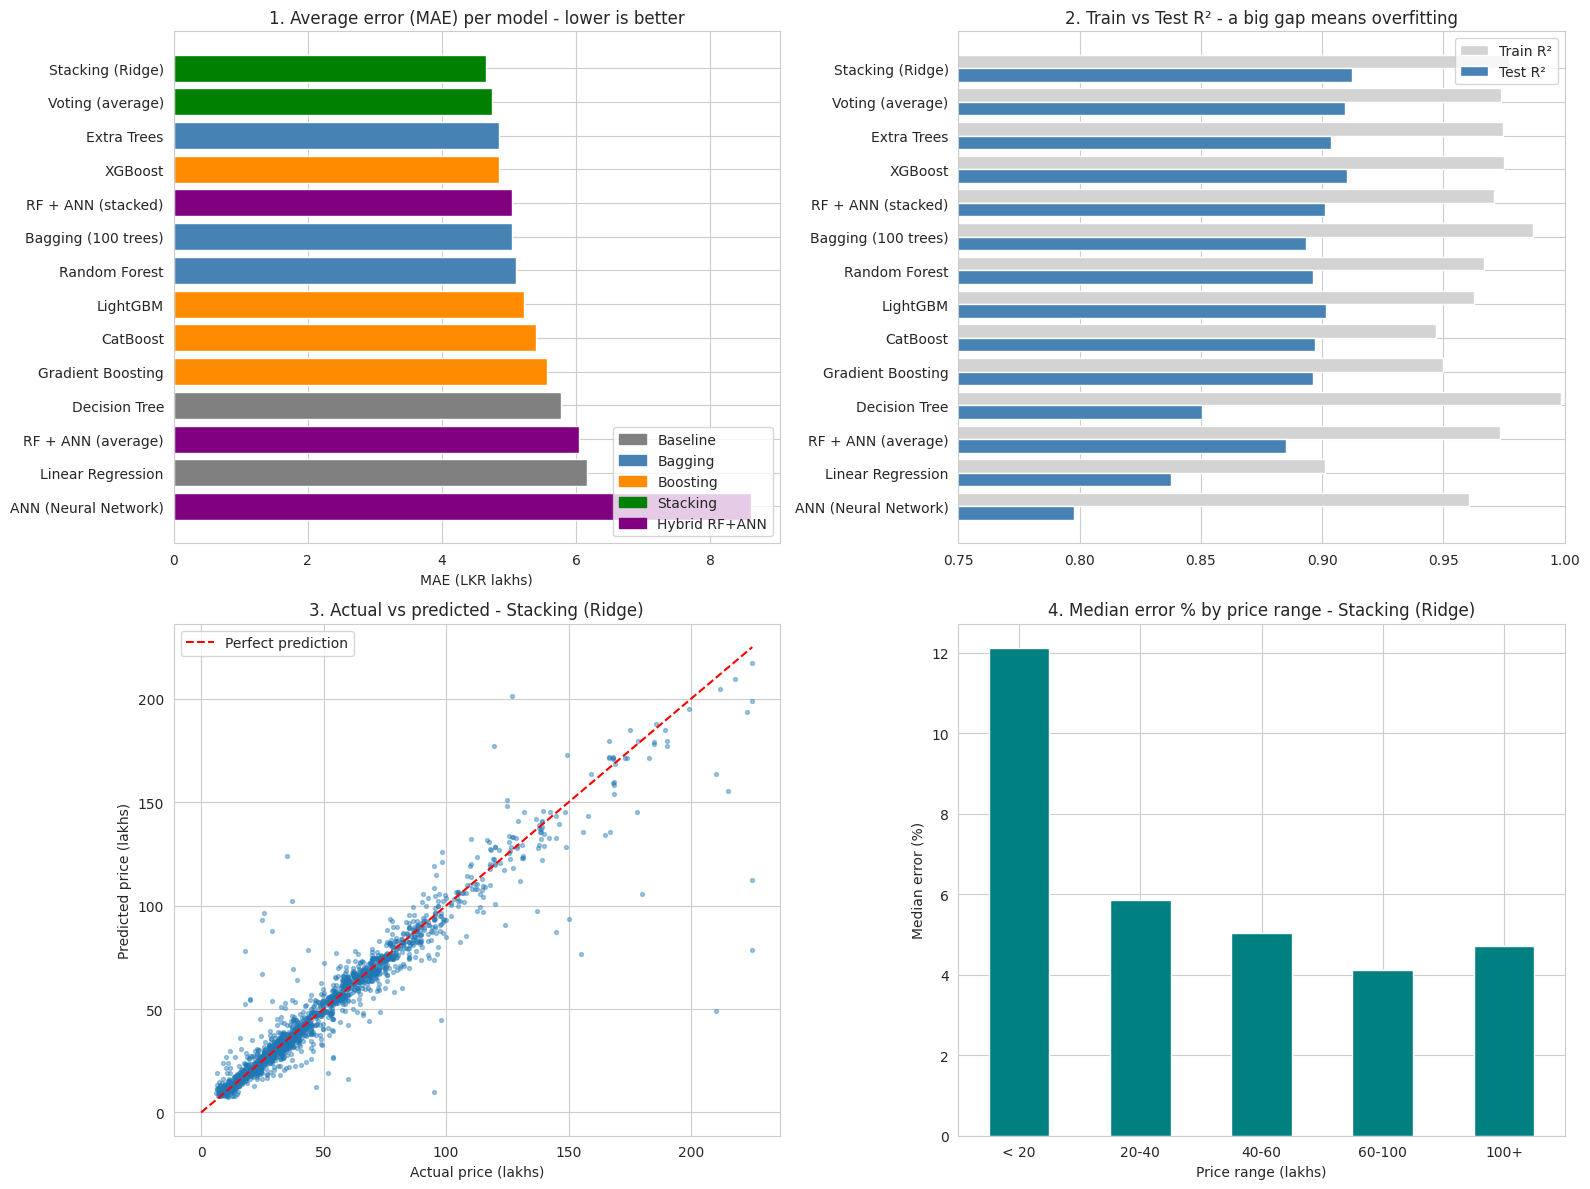

Best model: Stacking (Ridge)  |  MAE = 4.65 lakhs  |  MAPE = 11.2%  |  R2 = 0.913


In [17]:
# ---------- 1. Results table ----------
res = (pd.DataFrame(results)
         .drop_duplicates("Model", keep="last")      # keep the latest run of each model
         .set_index("Model"))
res["Overfit gap"] = res["R2 train"] - res["R2 test"]
res = res.sort_values("MAE (lakhs)")

display(res.round(3).style.background_gradient(subset=["MAE (lakhs)"], cmap="RdYlGn_r"))

# ---------- 2. Charts ----------
colors = {"Baseline": "gray", "Bagging": "steelblue", "Boosting": "darkorange",
          "Stacking": "green", "Hybrid RF+ANN": "purple"}
bar_colors = [colors[g] for g in res["Group"]]

fig, ax = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: MAE per model
ax[0, 0].barh(res.index, res["MAE (lakhs)"], color=bar_colors)
ax[0, 0].invert_yaxis()
ax[0, 0].set_title("1. Average error (MAE) per model - lower is better")
ax[0, 0].set_xlabel("MAE (LKR lakhs)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax[0, 0].legend(handles, colors.keys(), loc="lower right")

# Chart 2: Train vs test R2
pos = np.arange(len(res))
ax[0, 1].barh(pos - 0.2, res["R2 train"], height=0.4, label="Train R²", color="lightgray")
ax[0, 1].barh(pos + 0.2, res["R2 test"], height=0.4, label="Test R²", color="steelblue")
ax[0, 1].set_yticks(pos)
ax[0, 1].set_yticklabels(res.index)
ax[0, 1].invert_yaxis()
ax[0, 1].set_xlim(0.75, 1.0)
ax[0, 1].set_title("2. Train vs Test R² - a big gap means overfitting")
ax[0, 1].legend()

# Chart 3: Actual vs predicted for the best model
best_name = res.index[0]
best_model = trained[best_name]
if best_name == "CatBoost":
    best_X_test = X_raw_test
elif best_name in ["LightGBM", "Stacking (Ridge)", "Voting (average)"]:
    best_X_test = X_test_lgb
else:
    best_X_test = X_test
best_pred = np.exp(best_model.predict(best_X_test))
actual = np.exp(y_test)

ax[1, 0].scatter(actual, best_pred, s=8, alpha=0.4)
ax[1, 0].plot([0, actual.max()], [0, actual.max()], "r--", label="Perfect prediction")
ax[1, 0].set_xlabel("Actual price (lakhs)")
ax[1, 0].set_ylabel("Predicted price (lakhs)")
ax[1, 0].set_title(f"3. Actual vs predicted - {best_name}")
ax[1, 0].legend()

# Chart 4: Error % by price range
error_pct = (best_pred - actual).abs() / actual * 100
price_band = pd.cut(actual, bins=[0, 20, 40, 60, 100, 250],
                    labels=["< 20", "20-40", "40-60", "60-100", "100+"])
band_error = error_pct.groupby(price_band, observed=True).median()
band_error.plot(kind="bar", ax=ax[1, 1], color="teal")
ax[1, 1].set_title(f"4. Median error % by price range - {best_name}")
ax[1, 1].set_xlabel("Price range (lakhs)")
ax[1, 1].set_ylabel("Median error (%)")
ax[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(f"Best model: {best_name}  |  MAE = {res.loc[best_name, 'MAE (lakhs)']:.2f} lakhs  |  "
      f"MAPE = {res.loc[best_name, 'MAPE (%)']:.1f}%  |  R2 = {res.loc[best_name, 'R2 test']:.3f}")

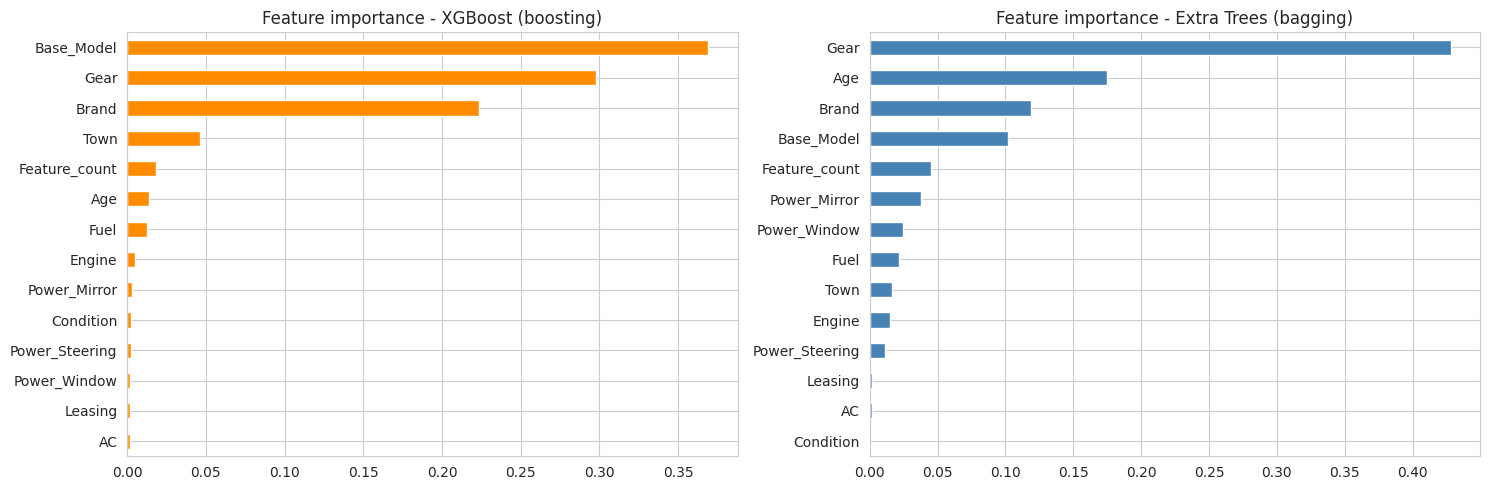

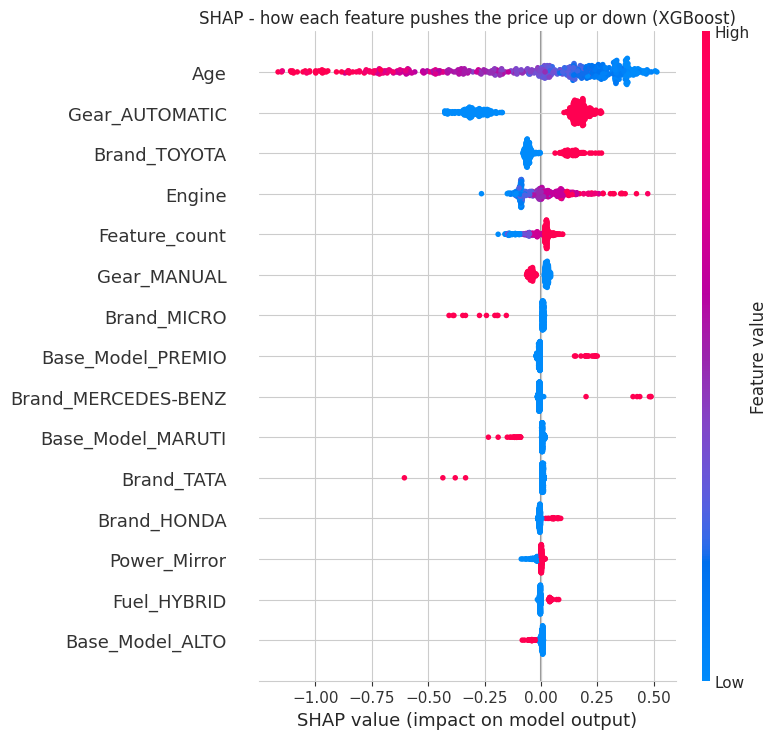

In [18]:
import shap

# ---------- 1. Combine one-hot columns back into their original feature ----------
def original_feature(col):
    for cat in cat_cols:
        if col.startswith(cat + "_"):
            return cat
    return col

def grouped_importance(model, columns):
    imp = pd.Series(model.feature_importances_, index=columns)
    return imp.groupby(original_feature).sum().sort_values()

imp_xgb = grouped_importance(trained["XGBoost"], X_train.columns)
imp_et = grouped_importance(trained["Extra Trees"], X_train.columns)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
imp_xgb.plot(kind="barh", ax=ax[0], color="darkorange", title="Feature importance - XGBoost (boosting)")
imp_et.plot(kind="barh", ax=ax[1], color="steelblue", title="Feature importance - Extra Trees (bagging)")
plt.tight_layout()
plt.show()

# ---------- 2. SHAP: direction of each feature's effect (XGBoost) ----------
sample = X_test.sample(500, random_state=42)
explainer = shap.TreeExplainer(trained["XGBoost"])
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, max_display=15, show=False)
plt.title("SHAP - how each feature pushes the price up or down (XGBoost)")
plt.tight_layout()
plt.show()

### Interpretation: what drives used-car prices in Sri Lanka?

**SHAP shows the top price drivers:**
1. **Age:** the strongest factor. Newer cars are priced much higher, which reflects depreciation.
2. **Automatic gear:** a large premium over manual (automatics are newer and in higher demand).
3. **Brand Toyota:** a clear premium, due to Toyota's reputation for reliability and resale value in Sri Lanka.
4. **Engine capacity:** larger engines raise the price (Sri Lankan import tax increases with cc).
5. **Comfort features:** cars with all four features (AC, power steering, mirrors, windows) sell for more.
- **Brands that lower prices:** Micro (locally assembled), Tata and Maruti (budget Indian brands), and the Alto (entry-level).
- **Models that raise prices:** Mercedes-Benz and Toyota Premio.
- **Hybrid** adds only a small premium in SHAP. Most of its effect is already captured by Age and Brand, because hybrids are mostly newer Toyotas and Hondas.

**Why the importance methods disagree:**
- XGBoost's built-in importance ranks **Age low**, while SHAP ranks it **first**. Built-in importance averages the gain per split: Age is used in many splits with small gains each, while rare one-hot columns are used in few splits with large gains.
- Adding up hundreds of one-hot columns also **inflates Brand and Base_Model** simply because they have many columns.
- Extra Trees ranks **Gear first** because its random splits favour the simple automatic/manual divide, and Gear acts partly as a **stand-in for age**: older cars are mostly manual.
- **Conclusion:** built-in tree importance is biased toward one-hot and high-cardinality features. **SHAP gives a fairer picture**, because it measures each feature's actual contribution to every prediction.

In [19]:
import joblib, os, sklearn, xgboost, lightgbm

os.makedirs("artifacts", exist_ok=True)

# ---------- 1. Save the best model (fall back to XGBoost if too big for GitHub) ----------
deploy_name = res.index[0]
joblib.dump(trained[deploy_name], "artifacts/model.pkl", compress=3)
size_mb = os.path.getsize("artifacts/model.pkl") / 1e6

if size_mb > 95:
    print(f"{deploy_name} is {size_mb:.0f} MB - too big for GitHub, saving XGBoost instead")
    deploy_name = "XGBoost"
    joblib.dump(trained[deploy_name], "artifacts/model.pkl", compress=3)
    size_mb = os.path.getsize("artifacts/model.pkl") / 1e6

print(f"Saved model: {deploy_name} ({size_mb:.1f} MB)")

# Stacking / Voting / LightGBM were trained on the cleaned column names
uses_clean_names = deploy_name in ["Stacking (Ridge)", "Voting (average)", "LightGBM"]
model_columns = list(X_train_lgb.columns if uses_clean_names else X_train.columns)

# ---------- 2. Save everything the dashboard needs ----------
model_info = {
    "model_name": deploy_name,
    "columns": model_columns,
    "clean_names": uses_clean_names,
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "ref_year": 2025,                                   # listings are from Dec 2024 - Feb 2025
    "brand_models": df.groupby("Brand")["Base_Model"].unique().apply(sorted).to_dict(),
    "towns": sorted(df["Town"].unique()),
    "fuels": sorted(df["Fuel"].unique()),
    "gears": sorted(df["Gear"].unique()),
    "conditions": sorted(df["Condition"].unique()),
    "yom_range": (int(df["YOM"].min()), int(df["YOM"].max())),
    "engine_median": float(df["Engine"].median()),
    "scores": res.loc[deploy_name, ["MAE (lakhs)", "MAPE (%)", "R2 test"]].to_dict(),
}
joblib.dump(model_info, "artifacts/model_info.pkl")

res.to_csv("artifacts/results.csv")
imp_xgb.sort_values(ascending=False).to_csv("artifacts/feature_importance.csv", header=["importance"])
ts_table.to_csv("artifacts/arima_results.csv")

print("Saved:", os.listdir("artifacts"))

# ---------- 3. Versions for requirements.txt ----------
print("\nrequirements.txt:")
print(f"scikit-learn=={sklearn.__version__}")
print(f"xgboost=={xgboost.__version__}")
print(f"lightgbm=={lightgbm.__version__}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print("joblib\nstreamlit\nplotly")

Saved model: Stacking (Ridge) (37.5 MB)
Saved: ['arima_results.csv', 'feature_importance.csv', 'results.csv', 'model_info.pkl', 'model.pkl']

requirements.txt:
scikit-learn==1.6.1
xgboost==3.4.1
lightgbm==4.6.0
pandas==2.2.3
numpy==2.4.6
joblib
streamlit
plotly


In [21]:
import joblib, numpy
print(joblib.__version__, numpy.__version__)

1.6.0 2.4.6
